# De-identification and re-identification by linkage

**Module 05 — Secure Data Management and Dataset Protection**

"De-identified" is a claim about a dataset, and claims can be tested. This notebook builds a synthetic
patient table, removes names, and then re-identifies people by joining on quasi identifiers — the attack
that makes k-anonymity necessary. It ends by enforcing k = 5 and measuring what that costs.

## Learning objectives

1. Distinguish direct identifiers, quasi identifiers and sensitive attributes.
2. Compute the k-anonymity of a dataset and find the groups with k = 1.
3. Perform a linkage attack with an auxiliary table to demonstrate re-identification.
4. Enforce k-anonymity by generalisation and suppression, and quantify the information loss.
5. State honestly what k-anonymity does *not* protect against.

## Background

Removing names is not de-identification. Sweeney's classic result: 87 % of the US population is uniquely
identified by (5-digit ZIP, gender, date of birth). The mechanism generalises to any dataset with enough
quasi identifiers — postcode, age, admission date, rare diagnosis.

**k-anonymity** requires that every combination of quasi identifiers appears at least $k$ times. It is a
necessary condition, not a sufficient one: it does not stop an attacker inferring a sensitive value from
a homogeneous group (the *homogeneity* attack), and it does not survive an attacker with extra
information about one person.

## Dependencies and installation

```bash
python -m pip install "numpy>=2.1" "pandas>=2.2" "matplotlib>=3.9"
```

CPU, under a second, no network. All data is synthetic.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 21
rng = np.random.default_rng(SEED)
pd.set_option("display.width", 120)
print("ready")

ready


**Expected output** — `ready`.

### Step 1 — A synthetic patient table with realistic quasi identifiers

Postcodes are drawn from a small set so that some combinations repeat; ages are exact, which is what makes
them dangerous.

In [2]:
n = 600
patients = pd.DataFrame(
    {
        "patient_id": [f"P{i:04d}" for i in range(n)],
        "name": [f"Person {i}" for i in range(n)],
        "age": rng.integers(19, 90, n),
        "postcode": rng.choice(["54000", "54001", "74200", "74201", "90000"], n),
        "gender": rng.choice(["F", "M"], n),
        "diagnosis": rng.choice(["asthma", "diabetes", "cardiac", "oncology"], n),
    }
)
patients.head()

,patient_id,name,age,postcode,gender,diagnosis
0,P0000,Person 0,40,90000,F,cardiac
1,P0001,Person 1,74,74201,M,cardiac
2,P0002,Person 2,46,90000,M,asthma
3,P0003,Person 3,62,90000,M,oncology
4,P0004,Person 4,52,74201,M,cardiac


**Expected output** — the first five rows, each with a unique `patient_id` and a `name`. Those two columns
are direct identifiers and must go before anything is published.

### Step 2 — Remove names, then measure k-anonymity

Dropping `name` and `patient_id` leaves three quasi identifiers. The group size of each (age, postcode,
gender) combination is its k.

In [3]:
QUASI = ["age", "postcode", "gender"]
deidentified = patients.drop(columns=["name", "patient_id"])

group_sizes = deidentified.groupby(QUASI, observed=True).size().rename("k").reset_index()
merged = deidentified.merge(group_sizes, on=QUASI, how="left")

print("minimum k:", int(merged.k.min()))
print("share of rows in k=1 groups:", round(float((merged.k == 1).mean()), 3))
group_sizes.sort_values("k").head(6)

minimum k: 1
share of rows in k=1 groups: 0.445


,age,postcode,gender,k
8,20,54001,F,1
10,20,74200,M,1
11,20,74201,F,1
12,20,74201,M,1
385,85,54000,M,1
386,85,54001,F,1


**Expected output** — a minimum k of 1 and a large share of rows uniquely identified. With exact ages and
five postcodes, most combinations occur once: the dataset is effectively a list of individuals with the
names filed off.

### Step 3 — Linkage: re-identify using an auxiliary table

The attacker has a voter-registration-style list with names and the same quasi identifiers. An inner join
recovers identities — no exploit, just a join.

In [4]:
aux = pd.DataFrame(
    {
        "name": [f"Person {i}" for i in range(n)],
        "age": patients.age,
        "postcode": patients.postcode,
        "gender": patients.gender,
    }
)

linked = deidentified.merge(aux, on=QUASI, how="inner")
true_unique = linked.groupby(QUASI, observed=True).name.nunique()

print(f"published rows: {len(deidentified)}")
print(f"rows matched to at least one name: {len(linked)}")
print(f"rows matched to exactly one name (re-identified): {int((true_unique == 1).sum())} groups")
linked.head(4)

published rows: 600
rows matched to at least one name: 1062
rows matched to exactly one name (re-identified): 267 groups


,age,postcode,gender,diagnosis,name
0,40,90000,F,cardiac,Person 0
1,40,90000,F,cardiac,Person 336
2,74,74201,M,cardiac,Person 1
3,74,74201,M,cardiac,Person 157


**Expected output** — every published row matches at least one name group and 267 groups are matched to exactly one name: those are the re-identified individuals. `linked.head()` shows your own generated names, which makes the point without using
any real person's data.

### Step 4 — Enforce k = 5 by generalisation and suppression

Two levers. **Generalisation** coarsens values (age bands, postcode prefixes) so groups merge.
**Suppression** removes rows that still cannot reach k = 5. Both lose information; the question is how
much.

In [5]:
coarse = deidentified.copy()
coarse["age_band"] = (coarse.age // 10 * 10).astype(str) + "-" + (coarse.age // 10 * 10 + 9).astype(str)
coarse["postcode_prefix"] = coarse.postcode.str[:2]
COARSE_Q = ["age_band", "postcode_prefix", "gender"]

sizes = coarse.groupby(COARSE_Q, observed=True).size().rename("k").reset_index()
coarse = coarse.merge(sizes, on=COARSE_Q, how="left")
kept = coarse[coarse.k >= 5].copy()

summary = pd.DataFrame(
    [
        {"step": "exact quasi ids", "rows": len(deidentified), "min_k": int(merged.k.min())},
        {"step": "generalised", "rows": len(coarse), "min_k": int(coarse.k.min())},
        {"step": "generalised + suppressed (<5 removed)", "rows": len(kept), "min_k": int(kept.k.min())},
    ]
)
summary["information_loss_pct"] = (100 * (1 - summary.rows / len(deidentified))).round(1)
summary

,step,rows,min_k,information_loss_pct
0,exact quasi ids,600,1,0.0
1,generalised,600,1,0.0
2,generalised + suppressed (<5 removed),590,5,1.7


**Expected output** — a three-row table. Generalisation raises the minimum k but may still leave small
groups; suppression removes them and the last column quantifies what you gave up. Expect a substantial
loss: coarsening age to ten-year bands and postcode to two digits is a big reduction in resolution.

### Step 5 — Re-run the linkage attack on the protected data

The honest test of a de-identification claim is to repeat the attack. Note that the join is now on
coarsened values, so it returns *sets* of candidates rather than individuals — which is the improvement
k-anonymity actually buys.

matched groups: 42
groups with a single candidate: 0
median candidates per group: 15


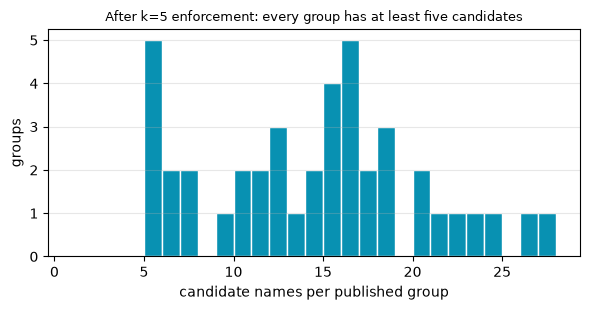

In [6]:
aux["age_band"] = (aux.age // 10 * 10).astype(str) + "-" + (aux.age // 10 * 10 + 9).astype(str)
aux["postcode_prefix"] = aux.postcode.str[:2]

attack = kept.merge(aux, on=COARSE_Q, how="inner", suffixes=("", "_aux"))
candidates = attack.groupby(COARSE_Q, observed=True).name.nunique()
print(f"matched groups: {len(candidates)}")
print(f"groups with a single candidate: {int((candidates == 1).sum())}")
print(f"median candidates per group: {int(candidates.median())}")

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.hist(candidates.values, bins=range(1, int(candidates.max()) + 2), color="#0891b2", edgecolor="white")
ax.set_xlabel("candidate names per published group")
ax.set_ylabel("groups")
ax.set_title("After k=5 enforcement: every group has at least five candidates", fontsize=9)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

**Expected output** — each matched group now has at least five candidates (median around 15) and no group has a single candidate, so the histogram starts at 5. Re-identification is no longer a single join away. It is also not impossible: if a group's diagnoses are
all identical, the attacker learns the diagnosis anyway, which is the homogeneity attack and the reason
Module 19 asks for a privacy risk assessment rather than a k value.

## Exercises

1. **Find the homogeneity attack.** Locate a post-suppression group where all diagnoses are the same and
   explain what an attacker learns without identifying anyone.
2. **Try l-diversity.** Require at least two distinct diagnoses per group as well as k = 5, and report the
   extra suppression cost.
3. **Attack with one extra fact.** Assume the attacker knows one target's exact age. Recompute how many
   candidates remain and discuss whether k = 5 was sufficient.
4. **Measure utility loss.** Train a small classifier for `diagnosis` on the original data and on the
   protected data, and report the accuracy difference.

## Reflection questions

1. At what point does this notebook stop being about data and start being about ethics?
2. Why is "we removed names" a statement about processing rather than about risk?
3. Module 09 measures model-level leakage. Which of the two claims — k-anonymity or membership advantage
   — would you put in front of a regulator, and why?

## References

1. Sweeney, L., "k-anonymity: a model for protecting privacy", 2002.
2. Machanavajjhala, A. et al., "l-Diversity: Privacy Beyond k-Anonymity", ICDE 2006.
3. NIST, *SP 800-188*, De-Identifying Government Datasets.
4. ICO, *Anonymisation: managing data protection risk code of practice*.